## Projeto 2 — Q-learning e Sarsa no Taxi-v4
Conceitos básicos de aprendizado por reforço e ambientes não determinísticos

**Integrantes:**
- Judite Mello
- Maria Eduarda dos Santos
- Mariana Machado 
- Marina 

Este relatório tem como objetivo treinar agentes utulizando os algoritmos Q-Learning e Sarsa em ambientes determinísticos não determinísticos. Através do cenrário Taxi-v4 em tempo seco e com chuva.
Serão realizados 5 treinamentos independentes para cada algoritmo. Por meio de gráficos e trabelas, será realizado a comparação entre o desempenho de aprendizado de cada agente.

Etapas:
1. Realização de 5 treinamentos para cada algoritmo.
2. Análise de 100 partidas, realizando a comparação entre o Q-learning e o Sarsa.
3. Criação de tabelas e gráficos comparando os algoritmos de aprendizado
4. Repetição do processo para o cenário indeterminístico com chuva.


Os módulos taxi_rl.py e taxi_report.py contêm a implementação reutilizada aqui. Este notebook pode carregar os dados entregues ou refazer todos os treinamentos.

## 1. Ambiente, recompensas e meta

O Taxi-v4 possui 500 estados e 6 ações: sul, norte, leste, oeste, pegar e deixar passageiro. Há 300 estados iniciais possíveis. A recompensa é −1 por passo comum, +20 pela entrega correta e −10 por tentativa ilegal de pegar/deixar. O retorno de um episódio é a soma não descontada das recompensas; o desconto γ é usado apenas na atualização dos valores Q.

Uma entrega em T passos, sem ações ilegais, tem retorno 21 − T. Portanto, +20 é a recompensa da entrega, não uma meta de retorno médio por episódio. O registro oficial estabelece **reward_threshold = 8** para o Taxi-v4 padrão. Usamos retorno médio ≥ 8 como referência operacional do ambiente seco.

Na chuva, is_rainy=True, rainy_probability=0.6 significa 60% de probabilidade de tentar a direção solicitada e 20% para cada lateral. Paredes ainda bloqueiam movimentos; pegar e deixar continuam determinísticos. O limiar 8 continua no registro, mas não foi recalibrado para a chuva.

Preservamos o wrapper TimeLimit de 200 passos. 

## 2. Hiperparâmetros

Ao todo, são 20 treinamentos: 5 Q-learning sem chuva, 5 com chuva, 5 Sarsa sem chuva e 5 Sarsa com chuva.

Cada tabela começa em zero e aprende por 20.000 episódios. As mesmas regras de α e ε valem para todos os grupos.

γ = 0,99: Valor próximo de 1 para dar valorizar ao máximo as recompensas futuras.

α inicial = 0,6: aprendizado rápido nas primeiras visitas. A redução por visita diminui a influência de transições isoladas na chuva sem alterar o protocolo entre algoritmos.

ε_start = 1.0: começa escolhendo as ações aleatoriamente

ε_min = 0.005: meta de escolha mínima para as ações aleatórias

ε_dec = 0.995: parâmetro de diminuição das escolhas aleatórias conforme o algoritmo aprende

3. Algoritmos e implementação
Q-learning (off-policy):

    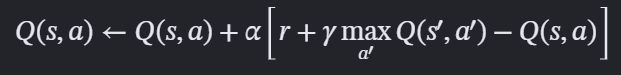
 

Sarsa (on-policy): primeiro sorteia a próxima ação pela política ε-greedy; essa é a ação usada no alvo e executada no passo seguinte:

![alt text](image.png)

## 3. Curvas de aprendizado


### Q-learning — sem chuva

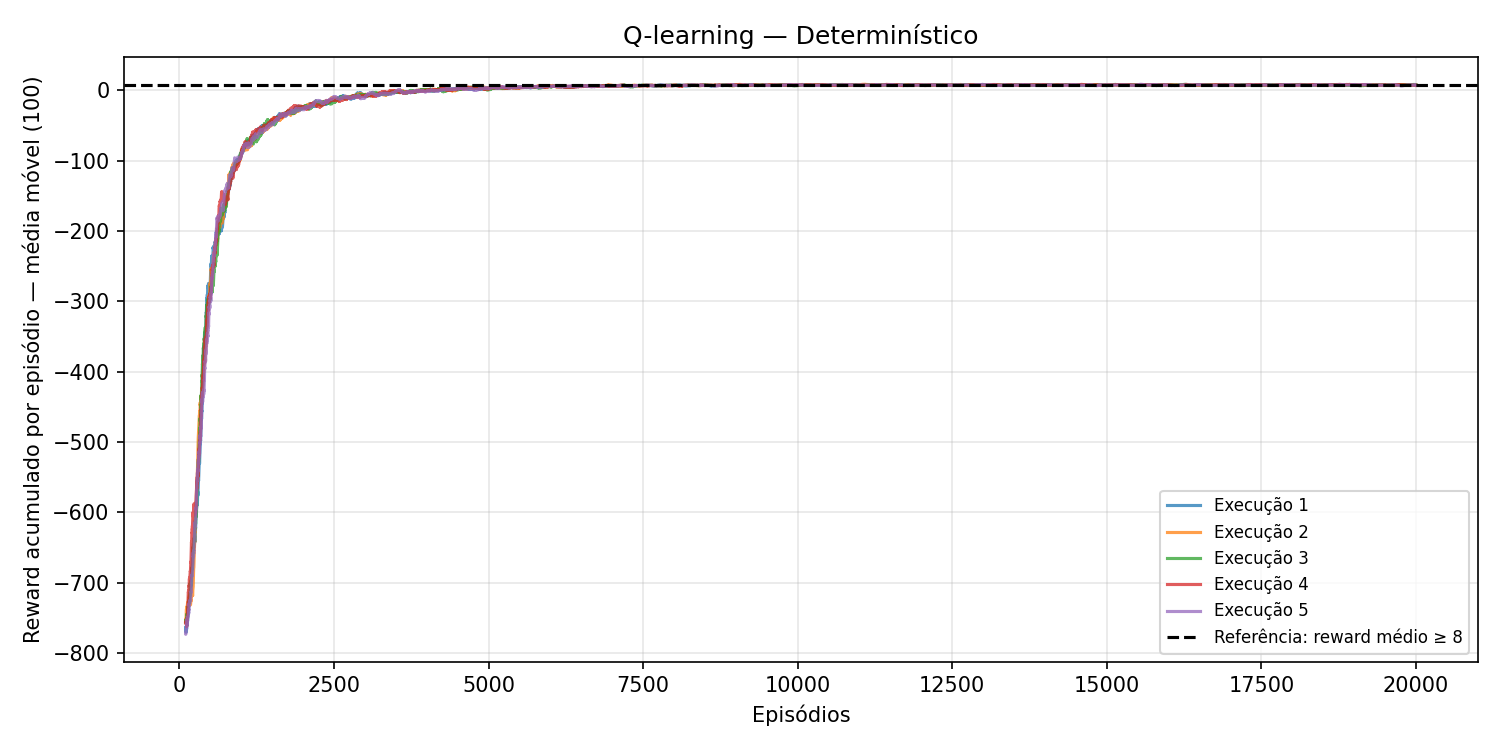

### SARSA — sem chuva

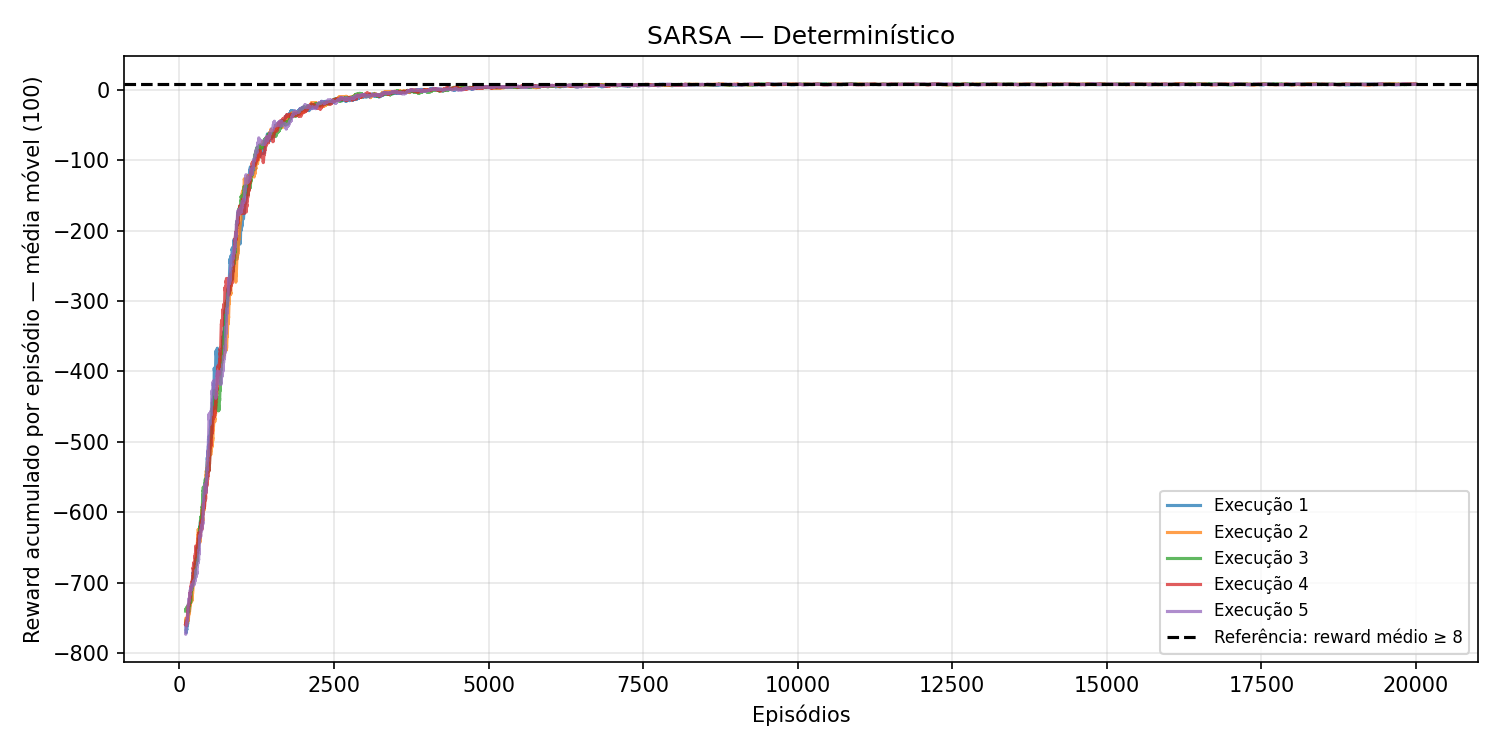

In [18]:
from IPython.display import Image, Markdown, display

graficos = [
    ("Q-learning — sem chuva", "q_learning_deterministico.png"),
    ("SARSA — sem chuva", "sarsa_deterministico.png")
]

for titulo, arquivo in graficos:
    display(Markdown(f"### {titulo}"))
    display(Image(filename=f"resultados/figuras/{arquivo}"))

Para um teste de 5 execução para cada algoritmo de aprendizado, nas mesmas circuntâncias, nesse caso o ambiente sem chuva e determinístico. Observa-se que  curva de aprendizado do Sarsa possui muito mais ruídos do que o Q-learning, mesmo a execução 4, ainda destoneia em vários pontos da 5° execução uma certa lentidão no aprendizado, demorando mais de 5.000 tentativas até chegar em uma estabilidade, aprender.
Já o algoritmo Q-learning em um ambiente determinístico demonstra aprender mais rápido, a sua curva de aprendizado é mais acentuada, e chega em uma estabilidade mais próximo dos 5.000 testes. Na 4° execução, já se mostra muito próximo à 5ª execução.
Outra observação importante é que ambos os algoritmos após aprendere, estabelizam o rearwd acumulado próximo a 0. 
No gráfico a baixo é possível notar essa variação com mais clareza:

### Comparação — sem chuva

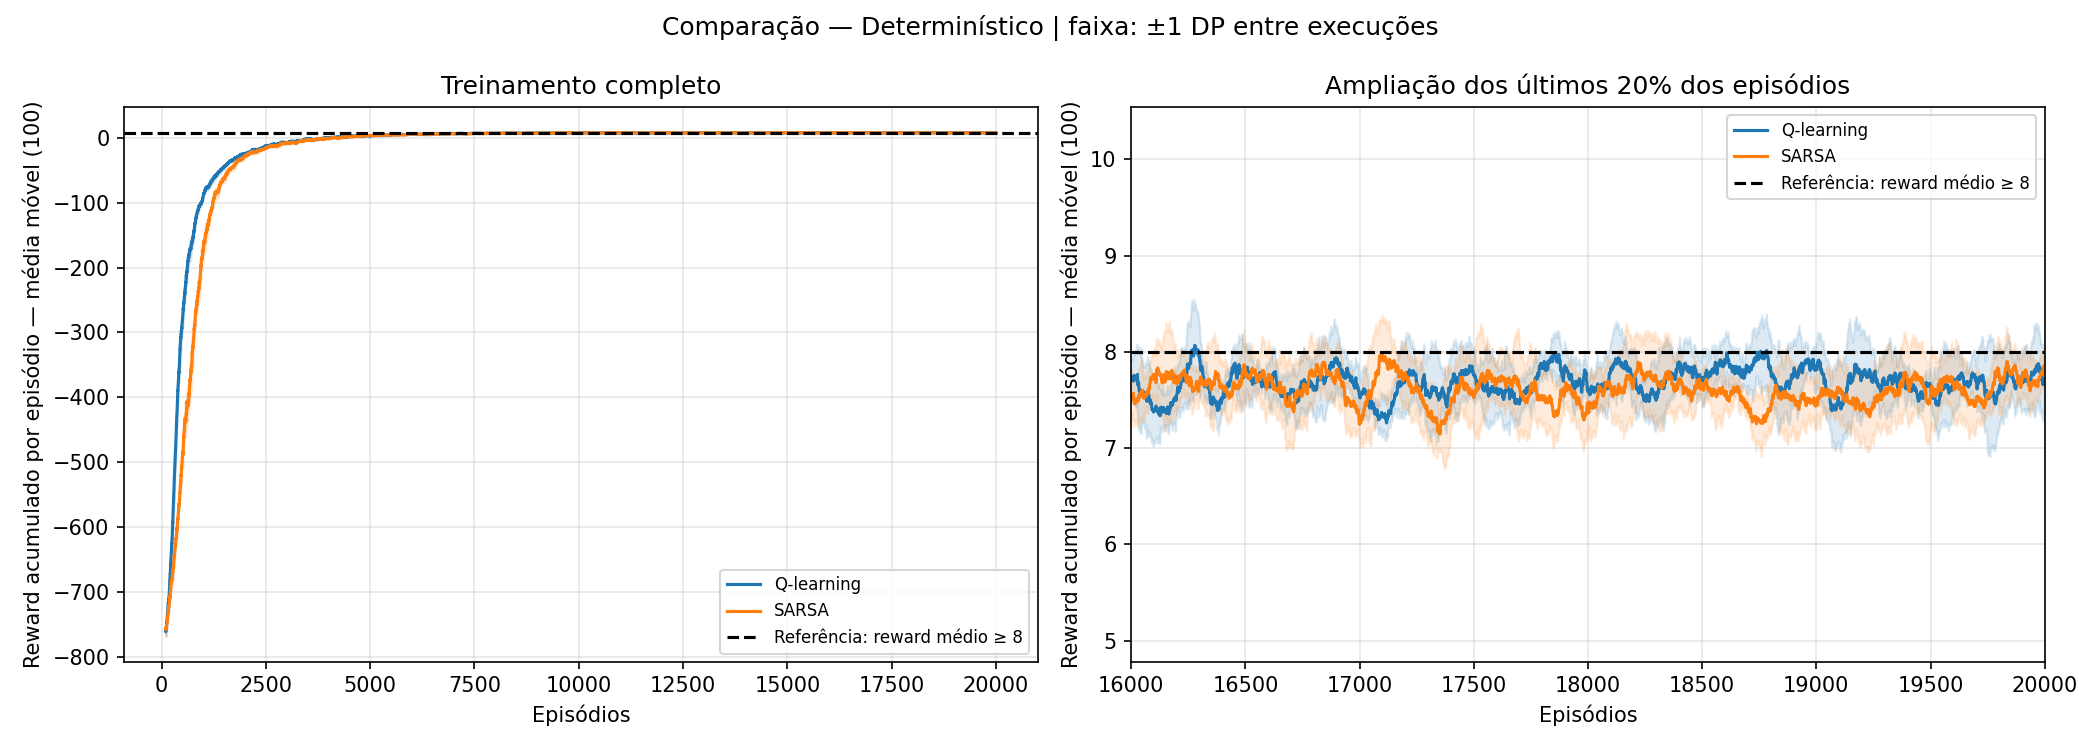

In [19]:
from IPython.display import Image, Markdown, display

grafico =  ("Comparação — sem chuva", "comparacao_deterministico.png")

display(Markdown(f"### {grafico[0]}"))
display(Image(filename=f"resultados/figuras/{grafico[1]}"))

## Comparação sem chuva
A curva de aprendizado do Q-learning acontee antes, mesmo partindo do mesmo ponto.
No gráfico a direita, temos uma ampliação do final da curva de aprendizado dos dois algoritmos. Podemos perceber que embora parecam que atingiram a estabilidade, ainda aprendentam variações. Porém, comparado com -800 do início e 8 o maior valor alcançado. As variações agora são muito menores, tendo diferença menor do que 1. 
Mas ainda assim, o algoritmo Q-learning fica mais próximo do 8 que é a nossa meta de reaward acumulado. 

### Q-learning — com chuva

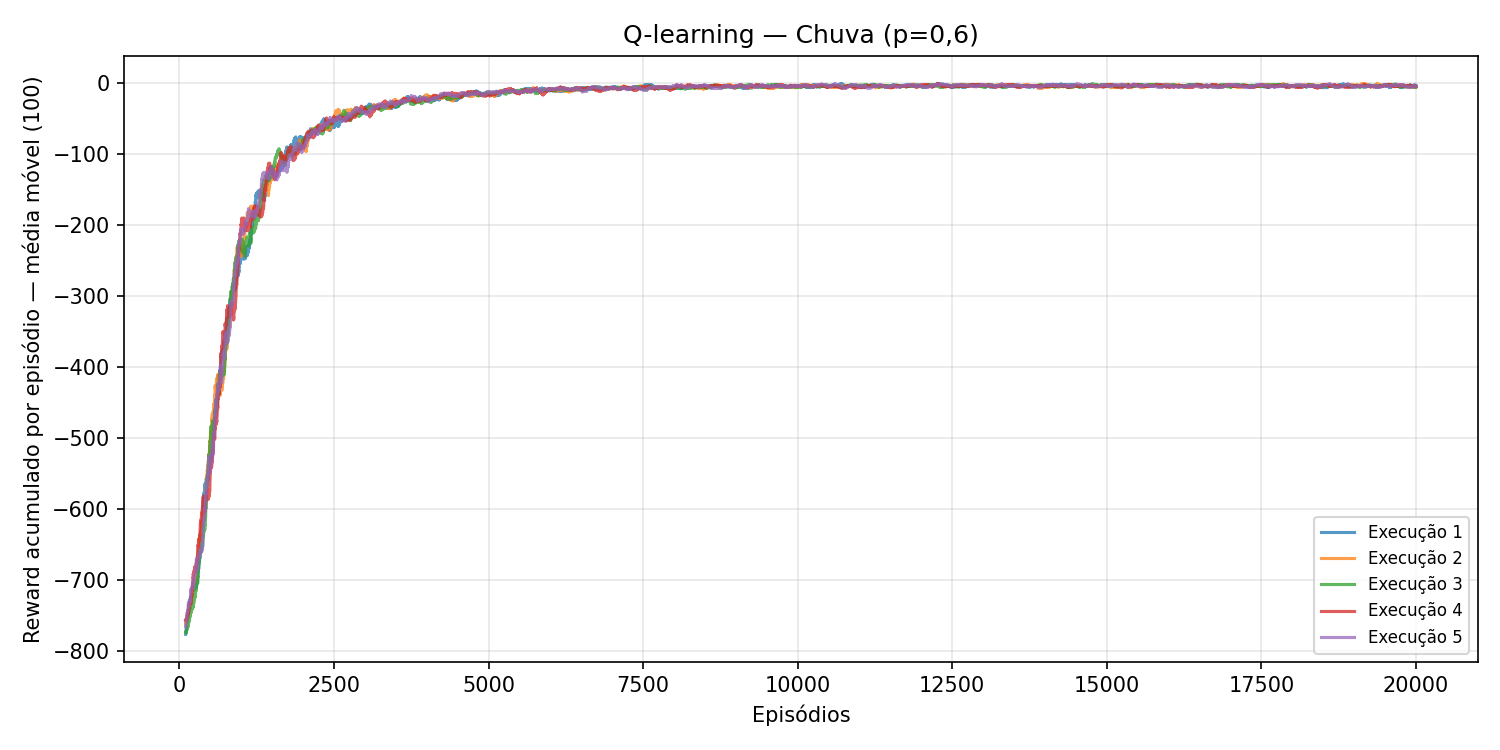

### SARSA — com chuva

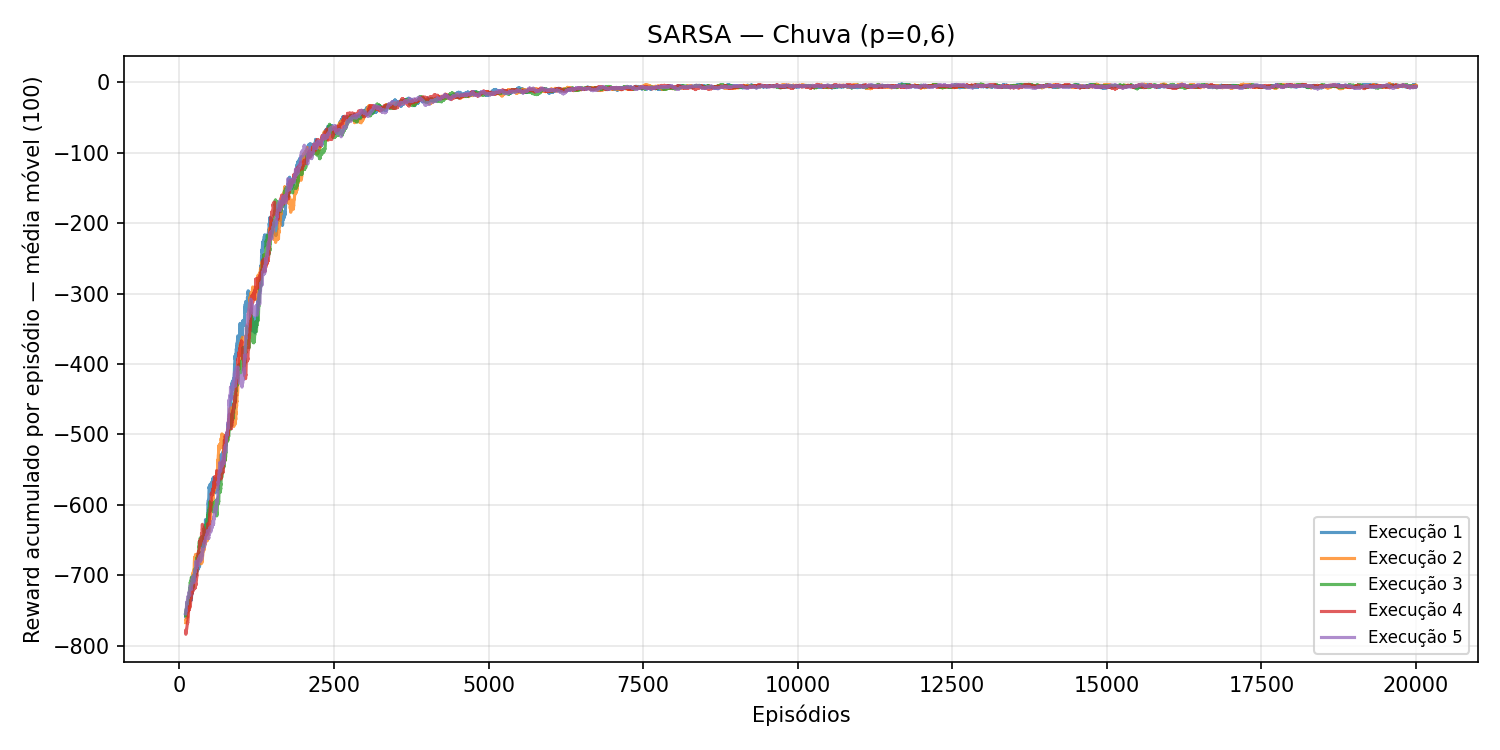

In [20]:
from IPython.display import Image, Markdown, display

graficos = [
    ("Q-learning — com chuva", "q_learning_chuva.png"),
    ("SARSA — com chuva", "sarsa_chuva.png")
]

for titulo, arquivo in graficos:
    display(Markdown(f"### {titulo}"))
    display(Image(filename=f"resultados/figuras/{arquivo}"))

## Análise com chuva

Quando consideramos o cenário com chuva, os ruíduos são muito maiores em ambos os algoritmos. Atingindo a estabilidade mais próximo de 10.000 episódios em Sarsa e entre 7.500 e 10.000 o Q-Learning. Ou seja, embora o algoritmo tente aprender, em um ambiente indeterminístico, é difícil estabelecer uma estabilidade e uma solução "coringa" para o problema.

### Comparação — com chuva

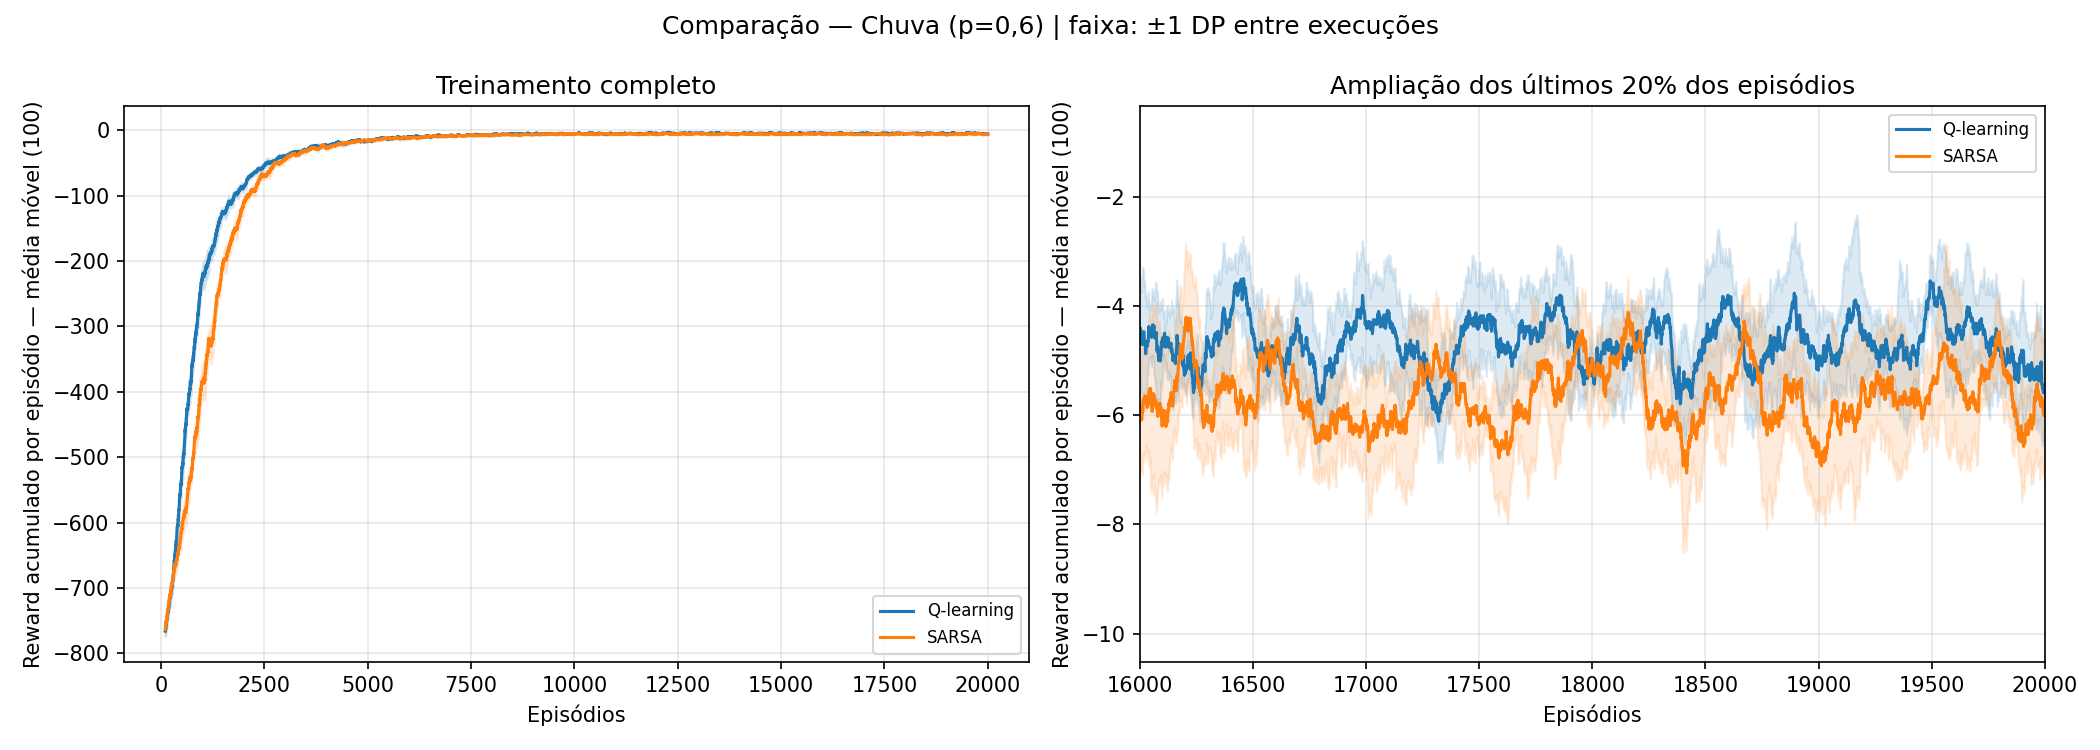

In [21]:
from IPython.display import Image, Markdown, display

grafico =  ("Comparação — com chuva", "comparacao_chuva.png")

display(Markdown(f"### {grafico[0]}"))
display(Image(filename=f"resultados/figuras/{grafico[1]}"))

## Comparação com Chuva

Observe que a curva de aprendizado do Q-learning continua precoce do que a Sarsa, ou seja, ainda assim, aprende mais rápido mas a estabilidade entre os dois acontece quase ao mesmo tempo.
Como mostrado no gráfico da direita, a variação nesse cenário indeterminístico é muito maior do que o determinpistico. Aqui, a variação passa de 2 e não chega próximo da meta 8 de reawards acumulados. 

In [22]:
import pandas as pd
from IPython.display import display, Markdown

resumo = pd.read_csv("resultados/resumo.csv")

grupos = [
    ("q_learning", "deterministico", "Q-learning — treinamento sem chuva"),
    ("q_learning", "chuva", "Q-learning — treinamento com chuva"),
    ("sarsa", "deterministico", "SARSA — treinamento sem chuva"),
    ("sarsa", "chuva", "SARSA — treinamento com chuva"),
]

for algoritmo, treino, titulo in grupos:
    grupo = resumo[
        (resumo["algoritmo"] == algoritmo)
        & (resumo["treino"] == treino)
    ].copy()

    # Primeiro os testes sem chuva, depois os testes com chuva.
    grupo["ordem_teste"] = grupo["teste"].map({
        "deterministico": 0,
        "chuva": 1
    })

    grupo = grupo.sort_values(["ordem_teste", "execucao"])

    grupo["teste"] = grupo["teste"].replace({
        "deterministico": "Sem chuva",
        "chuva": "Com chuva"
    })

    tabela = grupo[[
        "teste",
        "execucao",
        "sucessos",
        "falhas",
        "media_passos_sucessos",
        "dp_passos_sucessos"
    ]].rename(columns={
        "teste": "Ambiente de teste",
        "execucao": "Execução",
        "sucessos": "Entregas concluídas",
        "falhas": "Falhas",
        "media_passos_sucessos": "Média de passos",
        "dp_passos_sucessos": "Desvio padrão"
    })

    display(Markdown(f"### {titulo}"))

    display(
        tabela.style
        .format({
            "Média de passos": "{:.2f}",
            "Desvio padrão": "{:.2f}"
        }, na_rep="—")
        .hide(axis="index")
        .set_properties(**{
            "text-align": "center",
            "padding": "8px 14px"
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#24476b"),
                    ("color", "white"),
                    ("text-align", "center"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [
                    ("background-color", "#edf2f7"),
                    ("color", "#172b4d")
                ]
            }
        ])
    )

### Q-learning — treinamento sem chuva

Ambiente de teste,Execução,Entregas concluídas,Falhas,Média de passos,Desvio padrão
Sem chuva,1,100,0,13.04,2.47
Sem chuva,2,100,0,13.00,2.45
Sem chuva,3,100,0,13.00,2.45
Sem chuva,4,100,0,13.00,2.45
Sem chuva,5,100,0,13.02,2.45
Com chuva,1,100,0,25.69,8.71
Com chuva,2,100,0,25.34,8.51
Com chuva,3,100,0,25.88,8.42
Com chuva,4,100,0,25.57,8.74
Com chuva,5,100,0,25.69,8.57


### Q-learning — treinamento com chuva

Ambiente de teste,Execução,Entregas concluídas,Falhas,Média de passos,Desvio padrão
Com chuva,1,100,0,24.96,7.67
Com chuva,2,100,0,25.24,8.42
Com chuva,3,100,0,25.19,8.31
Com chuva,4,100,0,25.33,8.91
Com chuva,5,100,0,24.93,8.18


### SARSA — treinamento sem chuva

Ambiente de teste,Execução,Entregas concluídas,Falhas,Média de passos,Desvio padrão
Sem chuva,1,100,0,13.16,2.64
Sem chuva,2,100,0,13.06,2.46
Sem chuva,3,100,0,13.06,2.48
Sem chuva,4,100,0,13.10,2.52
Sem chuva,5,100,0,13.04,2.49
Com chuva,1,100,0,26.15,8.91
Com chuva,2,100,0,26.46,9.17
Com chuva,3,100,0,26.52,9.41
Com chuva,4,100,0,26.55,9.94
Com chuva,5,100,0,25.86,8.64


### SARSA — treinamento com chuva

Ambiente de teste,Execução,Entregas concluídas,Falhas,Média de passos,Desvio padrão
Com chuva,1,100,0,25.69,8.34
Com chuva,2,100,0,25.51,9.40
Com chuva,3,100,0,25.06,8.20
Com chuva,4,100,0,27.56,10.47
Com chuva,5,100,0,26.68,9.65
